# Phase 1: the cycle model

A **cycle model** follows the air through the engine (intake → compressor → combustor → turbine → nozzle) and applies conservation of mass and energy plus one efficiency per component. It returns thrust, fuel flow, and the temperature and pressure at every station.

We built two of them:
* `cycle_pycycle`: NASA's pyCycle, adapted to a micro turbojet;
* `cycle_simple`: our own independent 0-D model (≈5 ms per run instead of ≈1 s).

When two independent models agree under the same assumptions, a bug in either one is unlikely. That's *verification*. Agreement with real engines is a separate question; section 4 covers it.

In [1]:
import os, warnings
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd(); os.chdir(ROOT)
from turboml.physics.cycle_common import CycleInputs
from turboml.physics.cycle_simple import design_point
warnings.filterwarnings('ignore')
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']  # fixed categorical order
INK, MUTED, GRID = '#1f1f1e', '#6b6a63', '#e4e3dd'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'font.size': 10})

## 1. One engine, station by station
These are the baseline inputs from `configs/cycle_baseline.yaml`, with the pressure ratio and mass flow of a JetCat P160. The **component efficiencies are placeholders**; the YAML marks each value as an assumption, a datasheet value or a spec.

In [2]:
x = CycleInputs.from_yaml()
r = design_point(x)
print(f'Fn = {r.Fn_N:.1f} N   TSFC = {r.TSFC_kg_N_s*3600:.3f} kg/(N h) = {r.TSFC_g_kN_s:.1f} g/(kN s)   '
      f'FAR = {r.far:.4f}   EGT = {r.EGT_K-273.15:.0f} C   nozzle choked: {r.choked}')
names = {'0': 'free stream', '2': 'compressor in', '3': 'compressor out', '4': 'turbine in',
         '5': 'turbine out', '9': 'nozzle exit'}
pd.DataFrame({'station': [names[k] for k in r.stations],
              'Tt [K]': [s.Tt_K for s in r.stations.values()],
              'Pt [kPa]': [s.Pt_Pa / 1e3 for s in r.stations.values()]}, index=list(r.stations)).round(1)

Fn = 193.7 N   TSFC = 0.139 kg/(N h) = 38.7 g/(kN s)   FAR = 0.0197   EGT = 732 C   nozzle choked: False


,station,Tt [K],Pt [kPa]
0,free stream,288.2,101.3
2,compressor in,288.2,100.3
3,compressor out,459.2,351.1
4,turbine in,1150.0,333.5
5,turbine out,1004.9,163.5
9,nozzle exit,1004.9,163.5


## 2. Verification: pyCycle vs the 0-D model
We ran 64 Sobol-sampled designs through both models with identical inputs (ranges in `configs/phase1_crosscheck.yaml`: ground to 6 km, Mach 0–0.6, wide efficiency ranges). pyCycle uses CEA (equilibrium chemistry). Its faster TABULAR option was tested in Phase 1 and dropped: errors up to 3.5 % (docs/VALIDATION.md).

,median,max
Fn (primary),0.032%,1.034%
TSFC (primary),0.064%,0.932%
compressor power,0.000%,0.000%
SECONDARY |dFn|/Fg,0.025%,0.184%


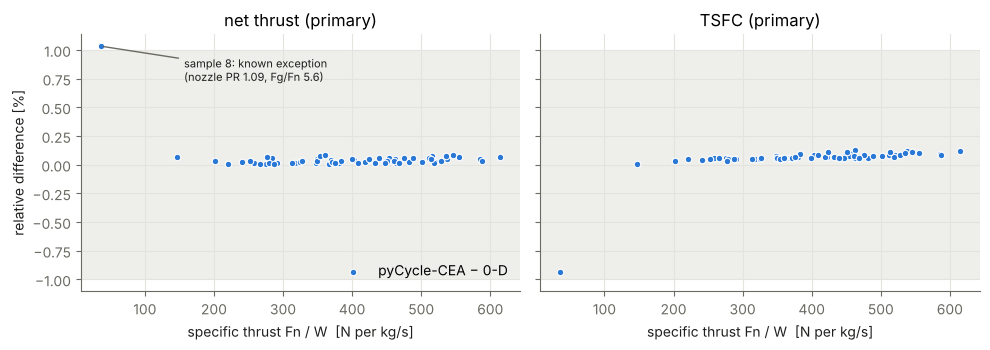

In [3]:
cc = pd.read_csv('validation/phase1/cross_check.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
st = cc.Fn_N_simple / cc.W_air_kg_s
for ax, q, label in zip(axes, ['Fn_N', 'TSFC_kg_N_s'], ['net thrust (primary)', 'TSFC (primary)']):
    ax.scatter(st, 100 * cc[f'{q}_reldiff'], s=22, color=SERIES[0], edgecolor='white',
               linewidth=0.8, zorder=3, label='pyCycle-CEA − 0-D')
    ax.axhspan(-1, 1, color=GRID, alpha=0.6, zorder=1, lw=0)
    ax.set(xlabel='specific thrust Fn / W  [N per kg/s]', title=label)
ex = cc[cc['sample'] == 8]
axes[0].annotate('sample 8: known exception\n(nozzle PR 1.09, Fg/Fn 5.6)', (st[ex.index[0]], 100 * ex.Fn_N_reldiff.iloc[0]),
                 xytext=(60, -25), textcoords='offset points', fontsize=8, color=INK, arrowprops=dict(arrowstyle='-', color=MUTED))
axes[0].set_ylabel('relative difference [%]'); axes[0].legend(frameon=False, loc='lower right')
axes[1].annotate('±1 % band', xy=(60, 1.15), color=MUTED, fontsize=9)
fig.tight_layout()
pd.DataFrame({k: [f'{cc[c].abs().median():.3%}', f'{cc[c].abs().max():.3%}'] for k, c in [
    ('Fn (primary)', 'Fn_N_reldiff'), ('TSFC (primary)', 'TSFC_kg_N_s_reldiff'),
    ('compressor power', 'P_comp_W_reldiff'), ('SECONDARY |dFn|/Fg', 'secondary_dFn_over_Fg')]},
    index=['median', 'max']).T

**How to read this:** median differences are a few hundredths of a percent. The one point above 1 % (sample 8) is a documented **known exception**: an engine with almost no net thrust (specific thrust ≈ 36, nozzle pressure ratio 1.09), where thrust is a small difference between two large numbers (jet momentum − ram drag), so a 0.03 % chemistry difference gets magnified about 31×. You accepted 63/64. The gross-thrust-relative difference is shown only as a labelled *secondary* metric; it never decides pass/fail.

## 3. Trends: what the cycle wants
Classic cycle behaviour, computed with the fast 0-D model. Higher pressure ratio cuts TSFC. Higher TIT raises specific thrust, so the engine gets smaller for the same thrust.

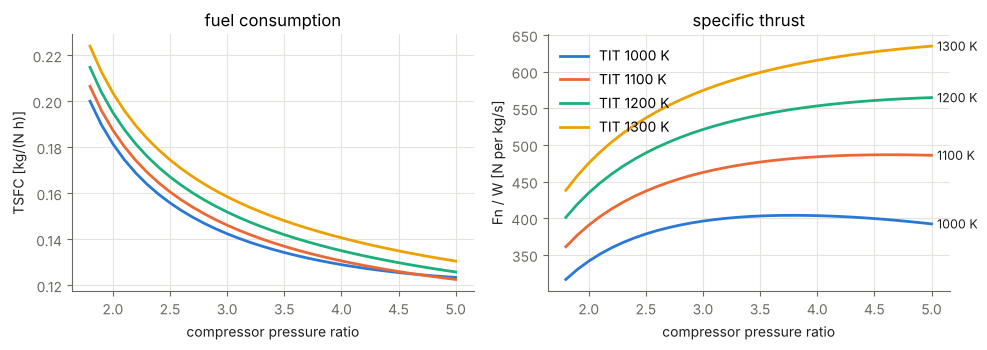

In [4]:
prs = np.linspace(1.8, 5.0, 33)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for i, tit in enumerate([1000, 1100, 1200, 1300]):
    res = [design_point(replace(x, pr_c=p, tit_K=tit)) for p in prs]
    ok = [rr.converged for rr in res]
    axes[0].plot(prs[ok], [rr.TSFC_kg_N_s * 3600 for rr, k in zip(res, ok) if k], color=SERIES[i])
    axes[1].plot(prs[ok], [rr.specific_thrust_N_s_kg for rr, k in zip(res, ok) if k], color=SERIES[i],
                 label=f'TIT {tit} K')
    axes[1].annotate(f'{tit} K', (prs[ok][-1], [rr.specific_thrust_N_s_kg for rr, k in zip(res, ok) if k][-1]),
                     xytext=(4, 0), textcoords='offset points', va='center', color=INK, fontsize=9)
axes[0].set(xlabel='compressor pressure ratio', ylabel='TSFC [kg/(N h)]', title='fuel consumption')
axes[1].set(xlabel='compressor pressure ratio', ylabel='Fn / W [N per kg/s]', title='specific thrust')
axes[1].legend(frameon=False, loc='upper left'); fig.tight_layout()

## 4. Sanity check against real engines (JetCat datasheets)
Five JetCat engines from 63 to 425 N publish pressure ratio, mass flow, thrust and SFC (`validation/cases/jetcat_datasheets.yaml`). **These values came from web-search extracts and are unverified.** 

**Forward:** placeholder efficiencies + the datasheet PR and mass flow → predicted thrust and SFC.

In [5]:
fwd = pd.read_csv('validation/phase1/jetcat_forward.csv')
fwd.assign(thrust_err=lambda d: (100 * d.thrust_err).round(1), sfc_err=lambda d: (100 * d.sfc_err).round(1))[
    ['engine', 'thrust_datasheet_N', 'thrust_model_N', 'thrust_err', 'sfc_datasheet', 'sfc_model', 'sfc_err']].round(3)

,engine,thrust_datasheet_N,thrust_model_N,thrust_err,sfc_datasheet,sfc_model,sfc_err
0,P62-RX,63,74.220,17.8,0.183,0.164,-10.5
1,P160-RXi-B,158,193.743,22.6,0.160,0.139,-12.9
2,P220-RXi,220,233.206,6.0,0.158,0.134,-15.3
3,P300-PRO,300,255.557,-14.8,0.157,0.139,-11.7
4,P400-PRO,425,346.046,-18.6,0.157,0.135,-14.0


SFC is under-predicted by 10–15 % for every engine, so the placeholder efficiencies are too optimistic for real micro engines.

**Inverse:** thrust and SFC give two equations, so for each assumed compressor efficiency η_c we solve for the TIT and turbine efficiency η_t that reproduce the datasheet *exactly*. Then we ask whether those implied values are physically plausible.

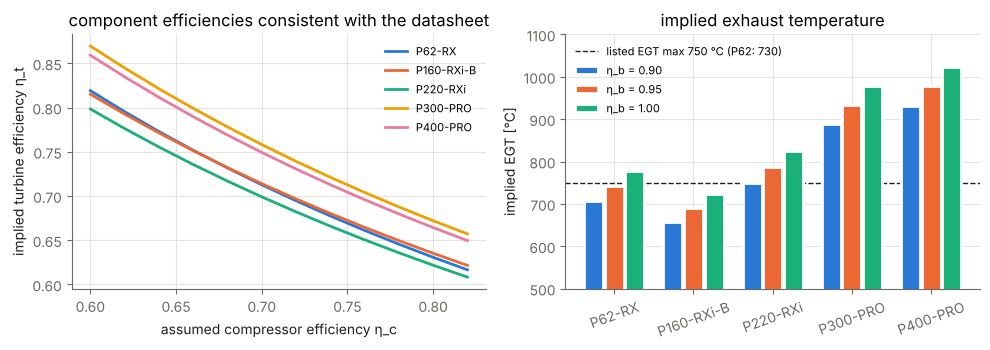

In [6]:
inv = pd.read_csv('validation/phase1/jetcat_inverse.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for i, (name, g) in enumerate(inv[inv.eta_burner == 0.95].groupby('engine', sort=False)):
    axes[0].plot(g.eta_c, g.eta_t, color=SERIES[i], label=name)
egt = inv[inv.eta_c == 0.70].pivot(index='engine', columns='eta_burner', values='egt_C')
egt = egt.loc[inv.engine.unique()]
for j, eb in enumerate(egt.columns):
    axes[1].bar(np.arange(len(egt)) + (j - 1) * 0.26, egt[eb], width=0.24, color=SERIES[j],
                edgecolor='white', linewidth=2, label=f'η_b = {eb:.2f}', zorder=3)
axes[1].axhline(750, color=INK, lw=1, ls='--', label='listed EGT max 750 °C (P62: 730)')
axes[0].set(xlabel='assumed compressor efficiency η_c', ylabel='implied turbine efficiency η_t',
            title='component efficiencies consistent with the datasheet')
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xticks(range(len(egt)), egt.index, rotation=20)
axes[1].set(ylabel='implied EGT [°C]', ylim=(500, 1100), title='implied exhaust temperature')
axes[1].legend(frameon=False, fontsize=8, loc='upper left'); fig.tight_layout()

**What this tells us:**
* By energy conservation, the exhaust temperature depends almost only on the fuel–air ratio, and fuel–air ratio = thrust × SFC / mass flow. So the implied EGT is nearly independent of the assumed component efficiencies.
* **P160** comes out consistent for any combustion efficiency, and **P62** if η_b ≤ 0.93: the implied EGT is then within the listed range, with η_t of 0.62–0.77 depending on η_c.
* **P300 and P400** come out inconsistent. Their numbers would need EGT ≈ 930–980 °C at η_b = 0.95, or a combustion efficiency of ≤ 0.70–0.74 to stay at the listed 750 °C. Either the extracted mass flow or thrust is wrong or measured differently, or the listed EGT isn't the mean exhaust total temperature (thermocouple placement). **We can't tell which without the official datasheets.**

## 5. A pitfall we found in pyCycle: fuel enthalpy
pyCycle's combustor has a fuel-enthalpy input that defaults to **0**, and its examples never set it. With pyCycle's thermo data, that makes C12H23 'kerosene' release ≈ 44.8 MJ/kg instead of ~43. Our wrapper sets it from the LHV. Here's the size of the effect (0-D model):

In [7]:
from turboml.gas.thermo import fuel_enthalpy_J_per_kg
lhv_default = -fuel_enthalpy_J_per_kg(0.0)  # LHV implied by h_fuel = 0
a = design_point(replace(x, eta_burner=1.0, lhv_J_kg=42.8e6))
b = design_point(replace(x, eta_burner=1.0, lhv_J_kg=lhv_default))
print(f'implied LHV with pyCycle default: {lhv_default/1e6:.2f} MJ/kg')
print(f'TSFC with LHV 42.8 MJ/kg: {a.TSFC_kg_N_s*3600:.4f};  with the pyCycle default: '
      f'{b.TSFC_kg_N_s*3600:.4f} kg/(N h)  ->  {100*(b.TSFC_kg_N_s/a.TSFC_kg_N_s-1):.1f} %')

implied LHV with pyCycle default: 44.85 MJ/kg
TSFC with LHV 42.8 MJ/kg: 0.1323;  with the pyCycle default: 0.1262 kg/(N h)  ->  -4.6 %


## Summary
* Two independent cycle models agree to ~0.1 % (pyCycle CEA vs 0-D), so verification passes except at one ill-conditioned point.
* The model can reproduce published thrust and SFC of the small JetCat engines with plausible component efficiencies. The larger PRO engines' extracted data looks inconsistent and needs checking.
* Component efficiencies are still **assumptions**. Sourcing them is the most important open item. See `docs/PHASE1_REPORT.md` for the decisions needed.